# DSC 411/511 Project
# Notebook 99: Summary: How I Moved Towards the Goals, What I Found, and References

This notebook collects the main results of notebooks 00-09 in one place. All numbers below are **read from the
files that the earlier notebooks saved** (folder `tables/`, in particular the `*_answer_numbers.csv` tables printed
just before each "Research Question -> Answer"). The text uses the same numbers, rounded.

---
# Section 1: The Path of the Project

1. **Starting point.** Three research questions on NFIP claims alone. With NFIP data only, the answers were weak
   (for example, RQ1 ROC-AUC 0.73 on unseen storms, and only 0.67 when whole storms were held out).
2. **Idea.** A claim is the result of *a building* (NFIP) meeting *a flood* (not in NFIP). So I added data about the
   flood and the place: **PRISM** daily rain, **NOAA HURDAT2** storm tracks, distance to the **coast**, **ACS**
   neighbourhood data and the **FEMA National Risk Index**.
3. **Frozen data** (notebook 00, Section 0.1): the exact file versions, sizes, row counts and SHA-256 hashes are saved
   in `tables/00_data_snapshot.json`, so the numbers below can be tied to one data version (NFIP claims as of
   2026-11-16, 2,731,064 rows).
4. **Careful EDA and cleaning** (notebook 01): every dropped row, dropped column, placeholder and imputed value is
   logged; a dedicated leakage section removed outcome-related fields, including a hidden leak found during the work
   (replacement cost is blank mostly on unpaid claims), and flags the storm's lifetime peak wind as a post-event feature.
5. **Feature reduction** (02) showed which data source carries information, and that PCA is not the right tool here.
6. **One notebook per question** (03-09): each starts from the class topic, explains the algorithm step by step,
   applies it with a **time split** (train 2020-2023, test 2024-2025) and an **event-grouped** cross-validation, and
   ends with an `answer_numbers` table and "Research question -> Answer". Each one compares **NFIP-only vs NFIP +
   external data**, and the main gains are checked with an **event-block bootstrap** (whole storms resampled).
7. **Published research** was reproduced where the data allowed it, then extended.

In [1]:
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import TABLE_DIR, FIGURE_DIR

pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)


def show_rows(answer_table, quantity_starts):
    """Print the rows of a notebook's answer_numbers table whose quantity starts with one of the given texts."""
    keep = answer_table['quantity'].apply(lambda q: any(str(q).startswith(start) for start in quantity_starts))
    print(answer_table.loc[keep, ['quantity', 'value']].to_string(index=False))

---
# Section 2: Data Actually Used

In [2]:
row_log = pd.read_csv(TABLE_DIR / '01_row_cleaning_log.csv')
print(row_log[['step', 'rows_removed', 'rows_after']].to_string(index=False))
cleaning_summary = json.load(open(TABLE_DIR / '01_cleaning_summary.json'))
print()
for key, value in cleaning_summary.items():
    print(f'{key:<35} {value}')
print()
print(pd.read_csv(TABLE_DIR / '00_external_join_coverage.csv').to_string(index=False))

# The frozen data snapshot (notebook 00, Section 0.1): every number in this project comes from these files
snapshot = json.load(open(TABLE_DIR / '00_data_snapshot.json'))
snapshot_table = pd.DataFrame(snapshot['files'])[['file', 'size_mb', 'downloaded_local_time', 'sha256']]
snapshot_table['sha256'] = snapshot_table['sha256'].str[:16] + '...'
print(f"\nData snapshot (written {snapshot['snapshot_written_local_time']}), claims file as of {snapshot['files'][0].get('data_as_of')}:")
print(snapshot_table.to_string(index=False))

                               step  rows_removed  rows_after
          0a. NFIP v3 national file             0     2731064
0b. loss date 2020-2025, CONUS only       2454945      276119
            1. exact duplicate rows           450      275669
    2. administrative error records         14531      261138
            3. no building coverage          6110      255028
           4. no latitude/longitude          1723      253305
    5. impossible building payments           181      253124

rows_after_cleaning                 253124
columns_after_cleaning              119
rows_removed_by_cleaning_steps      22995
columns_dropped                     30
columns_imputed                     35
placeholder_columns_fixed           11
large_loss_line_usd                 143519.0

                           feature  non_missing_pct
                  rain_loss_day_mm            99.34
                      rain_3day_mm            99.34
                      rain_7day_mm            99.34
       

| Source | What we took | Notes |
|---|---|---|
| OpenFEMA **NFIP Redacted Claims v3** (bulk parquet, 2,731,064 rows, as of 2026-11-16) | claims with loss date 2020-01-01 to 2025-12-31, CONUS | v3 is used because v2 is deprecated. 2025 is incomplete (reporting lag) |
| **PRISM** AN daily precipitation, 4 km (2,199 daily grids) | rain on loss day, 3-day and 7-day totals, max daily rain | PRISM day ends 12:00 UTC, so windows include day t+1; 3x3-cell mean around the 0.1-degree point |
| **NOAA HURDAT2** (Atlantic, 1851-2025) | nearest storm within +/- 3 days: distance, wind, Saffir-Simpson category | tracks interpolated to hourly; name matches FEMA's event label 97.6% |
| **Natural Earth** 10 m coastline | distance to coast | |
| **ACS 5-year 2019-2023** (Summary File tables B01003, B19013, B25077, B25003, B25035, C17002, B03002) | income, home value, % owner, median year built, % poverty, % non-Hispanic White, population | Census API now needs a key, so the bulk Summary File was used; block group 85%, tract 6%, county 8% |
| **FEMA National Risk Index v1.20** (counties) | coastal / riverine flood and hurricane risk, social vulnerability, resilience | matched for 99.4% of claims |
| **Census cartographic boundaries 2023** | county and state maps, Moran's I neighbours | |

| OpenFEMA **NFIP Redacted Policies v3** (74,778,941 records) | policies in force on 1 July 2020-2025, by census tract | used only in notebook 09 (take-up); v2 `FimaNfipPolicies` is deprecated |
| Census **2023 Gazetteer tracts**, **2020-2010 tract relationship file**, ACS tables **B25001, B25034** | tract points, moving 2010 codes to 2020 tracts, housing units, year built | notebook 09 |

Hawaii, Alaska and the territories are excluded because PRISM covers only the contiguous U.S.

---
# Section 3: Notebooks, Class Topics and Questions

| Notebook | Class topics | Question |
|---|---|---|
| 00 data acquisition and merging | L03 aggregation, sampling | Build one table: NFIP + PRISM + HURDAT2 + coast + ACS + NRI |
| 01 EDA and cleaning | L03 preprocessing, L13 outliers | What must be dropped, fixed, imputed? What would leak? |
| 02 feature reduction | L04 PCA, filters, mutual information | Can we reduce the features, and which source carries information? |
| 03 RQ1 positive building payment | L05 trees, naive Bayes; L06 k-NN; L07 logistic, SVM, evaluation; L14 MLP | Can building, policy and event data predict a positive payment? |
| 04 RQ2 large-loss flag | L07 imbalance, thresholds, ROC/PR | Can we flag damage above the P90 line before inspection? |
| 05 RQ3 clusters | L08 k-means, hierarchical; L09 DBSCAN; L10 validation; L16 autoencoder, t-SNE | Do building/policy features form meaningful groups? |
| 06 RQ4 association rules | L11 Apriori, FP-Growth; L12 lift, leverage, conviction, chi-squared | Which trait combinations travel with large losses? |
| 07 RQ5 rain vs surge, hotspots | L05 trees, L06 k-NN, L09 KDE and DBSCAN; spatial statistics | Is damage outside the SFHA rain-driven? Where are the hotspots? |
| 08 RQ6 equity | L07 logistic regression and odds; L03 discretization | Are lower-income areas paid less, after controlling for the flood? |
| 09 RQ7 protection gap | L03 aggregation; L05/07 tree regressor with grouped CV; L09-10 spatial clusters; count models; LISA | Do poorer, renter-heavy or older tracts file fewer claims per housing unit at the same hazard, and is it take-up? |

---
# Section 4: Key Results

Each block prints the key rows of the notebook's `answer_numbers` table, then gives the short answer.

## RQ1: positive building payment (notebook 03)

In [3]:
answer_03_rq1 = pd.read_csv(TABLE_DIR / '03_rq1_answer_numbers.csv')
show_rows(answer_03_rq1, ['ROC_AUC closed', 'PR_AUC closed', 'LightGBM time split', 'event-grouped', 'ablation', 'Brier', 'unpaid with blank reason, % of unpaid, 2025'])

                                                      quantity                                                            value
                   unpaid with blank reason, % of unpaid, 2025                                                             19.1
                  ROC_AUC closed claims: A -> B, gain [95% CI] 0.737 -> 0.793, +0.056 [+0.024, +0.129], gain in 100% of repeats
  ROC_AUC closed claims, without Helene: A -> B, gain [95% CI] 0.641 -> 0.730, +0.089 [+0.045, +0.148], gain in 100% of repeats
                   PR_AUC closed claims: A -> B, gain [95% CI] 0.352 -> 0.427, +0.075 [+0.025, +0.165], gain in 100% of repeats
   PR_AUC closed claims, without Helene: A -> B, gain [95% CI] 0.285 -> 0.396, +0.111 [+0.047, +0.185], gain in 100% of repeats
                  LightGBM time split A: ROC / PR-AUC not paid                                                    0.731 / 0.371
                  LightGBM time split B: ROC / PR-AUC not paid                                          

**Answer: partly, as a triage tool.** On closed 2024-2025 claims (103,530), NFIP-only LightGBM reaches ROC-AUC 0.737;
adding PRISM rain, storm and coast data raises it to 0.793 (gain +0.056, 95% event-bootstrap CI +0.024 to +0.129) and
PR-AUC for "not paid" from 0.352 to 0.427. Without Helene (51.5% of test claims) the gain is larger (ROC 0.641 -> 0.730).
The storm block and the rain block both matter (ablation: ROC -0.041 and -0.025 when removed); coast distance adds
little. ACS/NRI do not help on the time split (C 0.782 vs B 0.787). Event-grouped CV: 0.671 +/- 0.048 (A) vs
0.728 +/- 0.019 (C). The rain effect reversed in 2024-2025: unpaid "no flood damage" claims had *more* rain than paid
claims (median 81 vs 63 mm). Predicted payment chances are a little too low (mean 0.80 vs 0.87 observed; Brier 0.099 vs 0.118
for a constant). Threshold 0.65 (set on the 2020-22 model, 2023 validation): recall 0.49, precision 0.40 for "not paid".

## RQ2: large-loss flag (notebook 04)

In [4]:
answer_04_rq2 = pd.read_csv(TABLE_DIR / '04_rq2_answer_numbers.csv')
show_rows(answer_04_rq2, ['large-loss line', 'time split', 'bootstrap gain C', 'closed claims only: claims', 'ablation', 'Brier C', 'state vs national'])

                                                      quantity                                                                          value
         large-loss line (P90 of positive damage 2020-2023), $                                                                       143519.0
                         time split A. ROC / PR-AUC / lift@10%                                                           0.812 / 0.411 / 2.57
                         time split B. ROC / PR-AUC / lift@10%                                                           0.805 / 0.446 / 2.92
                         time split C. ROC / PR-AUC / lift@10%                                                           0.823 / 0.468 / 3.02
    bootstrap gain C. + event + context vs A, ROC_AUC [95% CI]                               +0.011 [+0.009, +0.041], gain in 100% of repeats
     bootstrap gain C. + event + context vs A, PR_AUC [95% CI]                               +0.057 [+0.042, +0.067], gain in 100% of repeats
bootst

**Answer: yes, as a ranking tool.** Line = $143,519 (P90 of positive damage, 2020-2023); 17.0% of the 99,664 test
claims are above it. NFIP-only already ranks well (ROC 0.812), and external data improves PR-AUC 0.411 -> 0.468 and
top-10% lift 2.6 -> 3.0 (PR-AUC gain +0.057, 95% CI +0.042 to +0.067). The ROC gain is small (+0.011). The storm block
makes most of the gain. Dropping open claims changes almost nothing; without Helene the gain is larger (PR-AUC
0.242 -> 0.302). The models under-predict in the severe test years (mean predicted 0.05 vs 0.17 observed), so use the
ranking, not the probability. Ghaedi et al.'s "state models beat national" was **not** reproduced at claim level.

## RQ3: building and policy clusters (notebook 05)

                                                              quantity                                                                                       value
                                                              chosen k                                                                                           4
                                                                reason k = 4 kept by design: its silhouette 0.175 beats all 20 noise datasets (max 0.149, z = 3.2)
                              k with largest silhouette gap over noise                                                                                           2
                                              k by Tibshirani gap rule                                                                                           7
              k=2: silhouette vs noise mean (SD), gap, z, beats all 20                                                0.254 vs 0.132 (0.066), +0.121, z=1.8, False
              k=4: sil

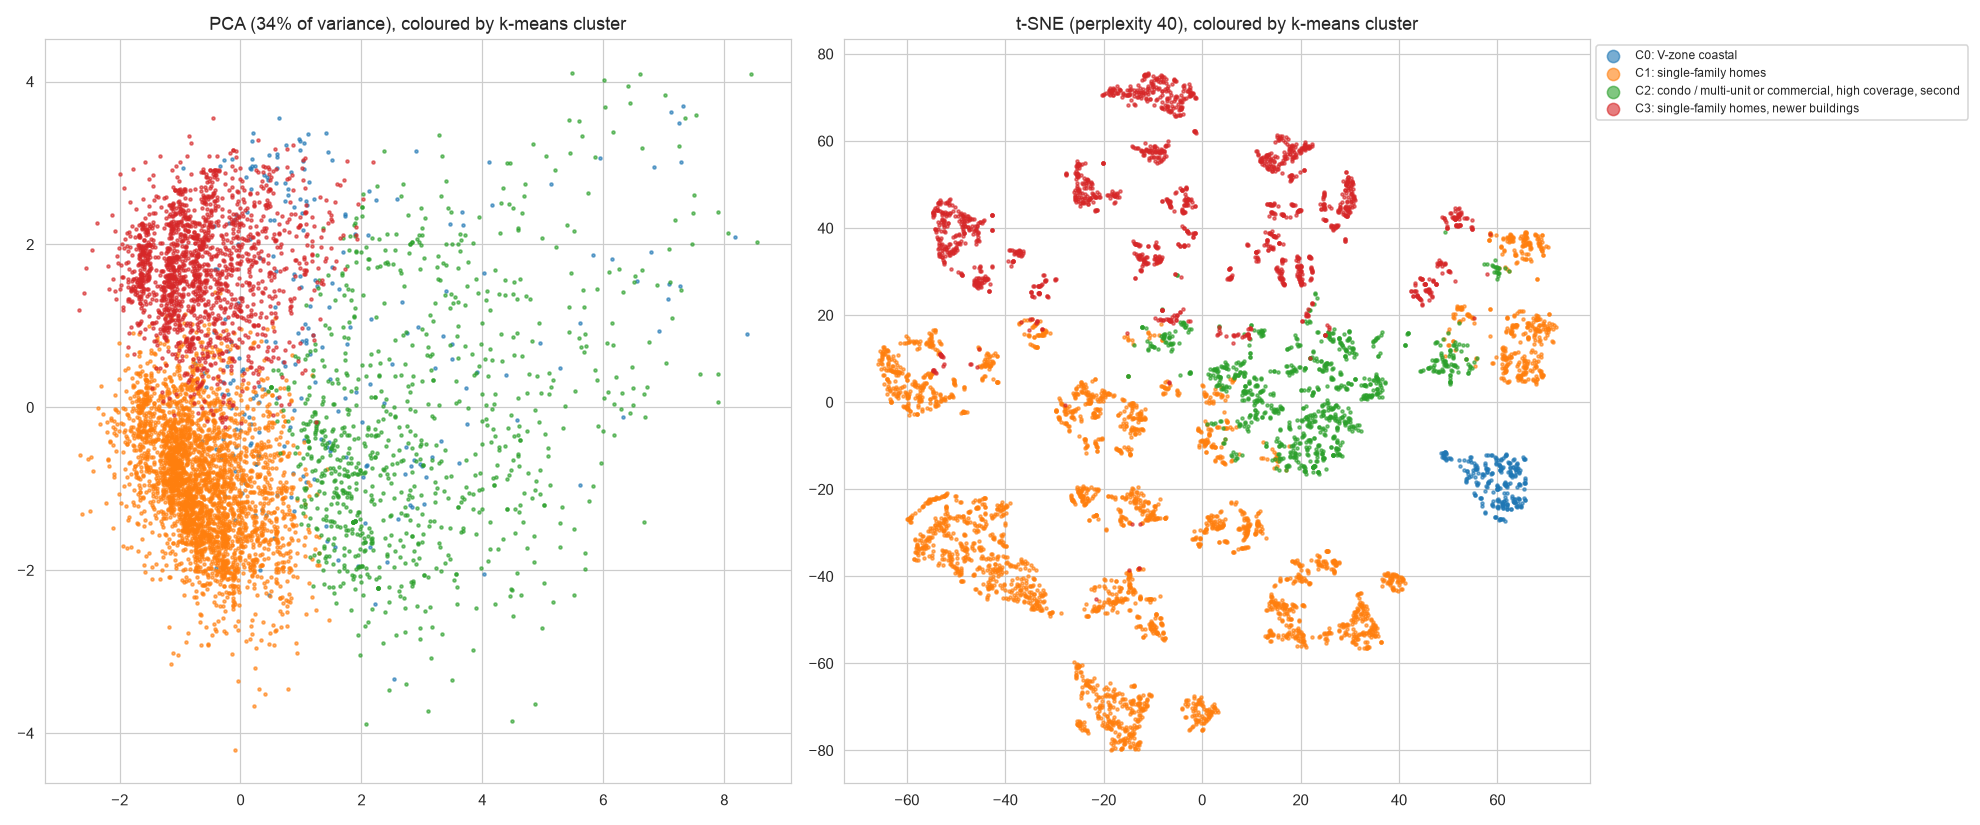

In [5]:
answer_05_rq3 = pd.read_csv(TABLE_DIR / '05_rq3_answer_numbers.csv')
show_rows(answer_05_rq3, ['chosen k', 'reason', 'k with largest', 'k by Tibshirani', 'k=2', 'k=4', 'seed ARI', 'C', "Cramer's V NFIP", "Cramer's V +", "Cramer's V occupancy_group vs large"])
display(Image(filename=str(FIGURE_DIR / '05_pca_tsne_by_cluster.png'), width=1000))

**Answer: real but weak groups; k = 4 kept as a design choice.** With 20 shuffled datasets per k, every k >= 4 beats
all noise sets (k = 4: silhouette 0.175 vs 0.119 +/- 0.017, z = 3.2). The criteria do not agree on one k: the largest
silhouette gap is at k = 2 (not robust to noise), the Tibshirani gap rule picks k = 7 (no clear elbow), and k = 6 has the
best silhouette (0.204). k = 4 gives four nameable groups (older pre-FIRM homes 53%, newer post-FIRM homes 28%,
condo/multi-unit 15%, V-zone 4%), stable across samples (ARI 0.98) but only partly across seeds (three of five 0.62).
The t-SNE layout is the same at perplexity 10, 40 and 100. Afterwards the groups differ in large-loss rate (5.5% to
26.9%), but one column (occupancy, V = 0.22) separates outcomes as well as the clusters (V = 0.20).

## RQ4: association rules (notebook 06)

In [6]:
answer_06_rq4 = pd.read_csv(TABLE_DIR / '06_rq4_answer_numbers.csv')
show_rows(answer_06_rq4, ['best', '  support', 'OUT_large_loss NFIP', 'OUT_large_loss: rules', 'OUT_not_paid: rules', 'all outcomes', 'top-12', 'top-6'])

                                                                quantity                                                                                value
                                                    best large-loss rule cat3plus_at_closest & condo_or_multiunit & coverage_at_250k_cap+  ->  OUT_large_loss
                                             support / confidence / lift                                                                 0.017 / 0.458 / 5.46
                                                      best not-paid rule                                               rain3d<25mm & zone=X  ->  OUT_not_paid
                                             support / confidence / lift                                                                 0.013 / 0.538 / 2.78
      OUT_large_loss NFIP items only: rules, best lift, top-10 mean lift                                                                      138, 4.83, 4.02
OUT_large_loss NFIP + external items: rules, best li

**Answer.** Condo/multi-unit + coverage at the cap + category 3+ storm -> large loss (lift 5.5 in training, 2.2 on
2024-2025). Low rain + zone X -> not paid (lift 2.8, then 3.7 on the test years). External items raise the best lift
for both outcomes (large loss 4.8 -> 5.5, not paid 1.8 -> 2.8). Of 624 outcome rules, 599 survive Benjamini-Hochberg
(569 Bonferroni), so chance is not the problem; change over time is (two of the top-12 large-loss rules fall below
lift 1 on the new storms).

## RQ5: rain vs surge and hotspots (notebook 07)

                                                        quantity                           value
  outside-SFHA claims coded rain/river/surge: % rain (all codes)                         66.0963
                  LightGBM A. NFIP only: macro-F1 / balanced acc                   0.579 / 0.600
LightGBM B. NFIP + event (PRISM, HURDAT: macro-F1 / balanced acc                   0.584 / 0.619
LightGBM C. NFIP + event + context (ACS: macro-F1 / balanced acc                   0.590 / 0.626
                 LightGBM macro-F1 gain B. + event vs A [95% CI]         +0.005 [-0.016, +0.061]
       LightGBM macro-F1 gain C. + event + context vs A [95% CI]         +0.011 [-0.011, +0.069]
                                                 DBSCAN hotspots                               8
      two largest hotspots: share of hotspot large-loss claims %                         92.9296
          Moran's I: raw rate, missing filled with 0 (Section 5) 0.449 (p = 0.002, 586 counties)
       Moran's I: raw rate, co

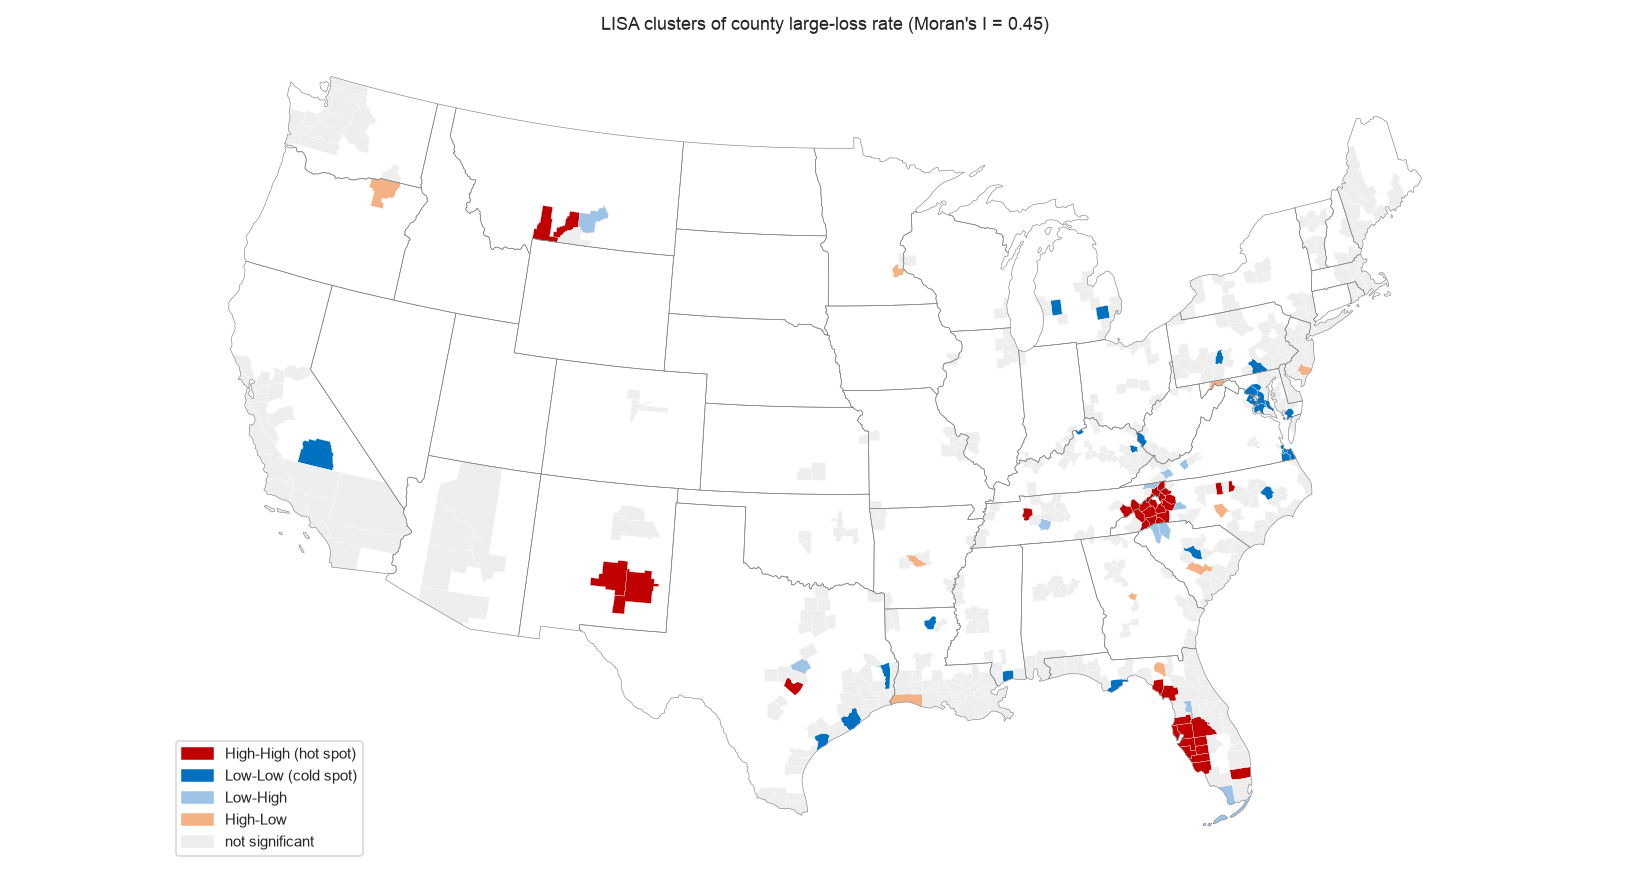

In [7]:
answer_07_rq5 = pd.read_csv(TABLE_DIR / '07_rq5_answer_numbers.csv')
show_rows(answer_07_rq5, ['outside-SFHA', 'LightGBM', 'DBSCAN', 'two largest', "Moran's I", 'counties filled', 'LISA'])
display(Image(filename=str(FIGURE_DIR / '07_lisa_large_loss.png'), width=1000))

**Answer.** (a) Outside the SFHA, 75.9% of rain/river/surge-coded claims are rain accumulation (Nelson-Mercer et
al.: 87.1% for 1978-2021); the share drops to 49.9% in 2022 (Ian). (b) The cause can be predicted only partly
(LightGBM macro-F1 0.58-0.59), and external data adds no clear gain for LightGBM (C vs A +0.011, 95% event-bootstrap CI
-0.011 to +0.069) because lat/lon and flood zone already encode the coast; it does help k-NN (0.45 -> 0.50).
(c) Large losses are strongly clustered: Moran's I = 0.45 (p = 0.002; 0.47 with empirical Bayes smoothing; the
`fillna(0)` affected 0 counties), 39 High-High and 28 Low-Low counties. DBSCAN finds 8 storm hotspots; Tampa Bay
(Helene) and Fort Myers (Ian) hold 93% of hotspot claims (76% of all large losses). Smaller urban hotspots
(Fort Lauderdale 2023, Louisiana, NY/NJ) are rain-driven, with 6-30% of large losses outside the SFHA.

## RQ6: equity (notebook 08)

In [8]:
answer_08_rq6 = pd.read_csv(TABLE_DIR / '08_rq6_answer_numbers.csv')
show_rows(answer_08_rq6, ['raw not-paid', 'Q1 vs Q5 odds ratio', 'Q1 vs Q5 payment', 'non-White', 'share of raw'])

                                                                             quantity                                               value
                                            raw not-paid rate Q1 lowest vs Q5 highest                                      0.176 vs 0.147
                                                   raw not-paid rate by majority race majority_NH_white: 0.157, majority_non_white: 0.210
                                        Q1 vs Q5 odds ratio not paid, M1 raw [95% CI]                         1.35 [1.03-1.77], p = 0.029
                          Q1 vs Q5 odds ratio not paid, M2 + building/policy [95% CI]                         1.26 [1.04-1.53], p = 0.017
              Q1 vs Q5 odds ratio not paid, M3 + flood exposure, state, year [95% CI]                         1.24 [1.02-1.51], p = 0.033
                          Q1 vs Q5 odds ratio not paid, M4 + adjuster damage [95% CI]                         1.22 [0.98-1.52], p = 0.072
                                  

**Answer.** Lowest-income block groups have higher odds of a claim closing without payment. **Main model (M3**:
building, policy, rain, storm, coast, state and year): **OR 1.24, 95% CI 1.02-1.51**, about 71% of the raw gap
(raw OR 1.35) remains. M4 also controls for the adjuster's damage estimate; because that estimate may itself carry
part of the gap (a bad control / mediator), it is only a sensitivity check (OR 1.22, CI 0.98-1.52). The
payment-per-dollar-of-damage gap is small (M3: -1.7 points, p = 0.10). Ecological, weak evidence: a reason to look
closer, not proof of unfair treatment.

## RQ7: protection gap (notebook 09)

                                                                  quantity                                                                                               value
                                                            exposed tracts                                                                                               17476
exposed tracts: housing units (M) / claims / share of tracts with no claim                                                                              30.6 / 212,628 / 43.9%
                      IRR (a) claims per housing unit, log_income [95% CI]                                                    1.00 [0.88-1.13], negative binomial (alpha 2.73)
                      IRR (a) claims per housing unit, pct_renter [95% CI]                                                    0.68 [0.62-0.75], negative binomial (alpha 2.73)
           IRR (a) claims per housing unit, pct_built_before_1980 [95% CI]                                                   

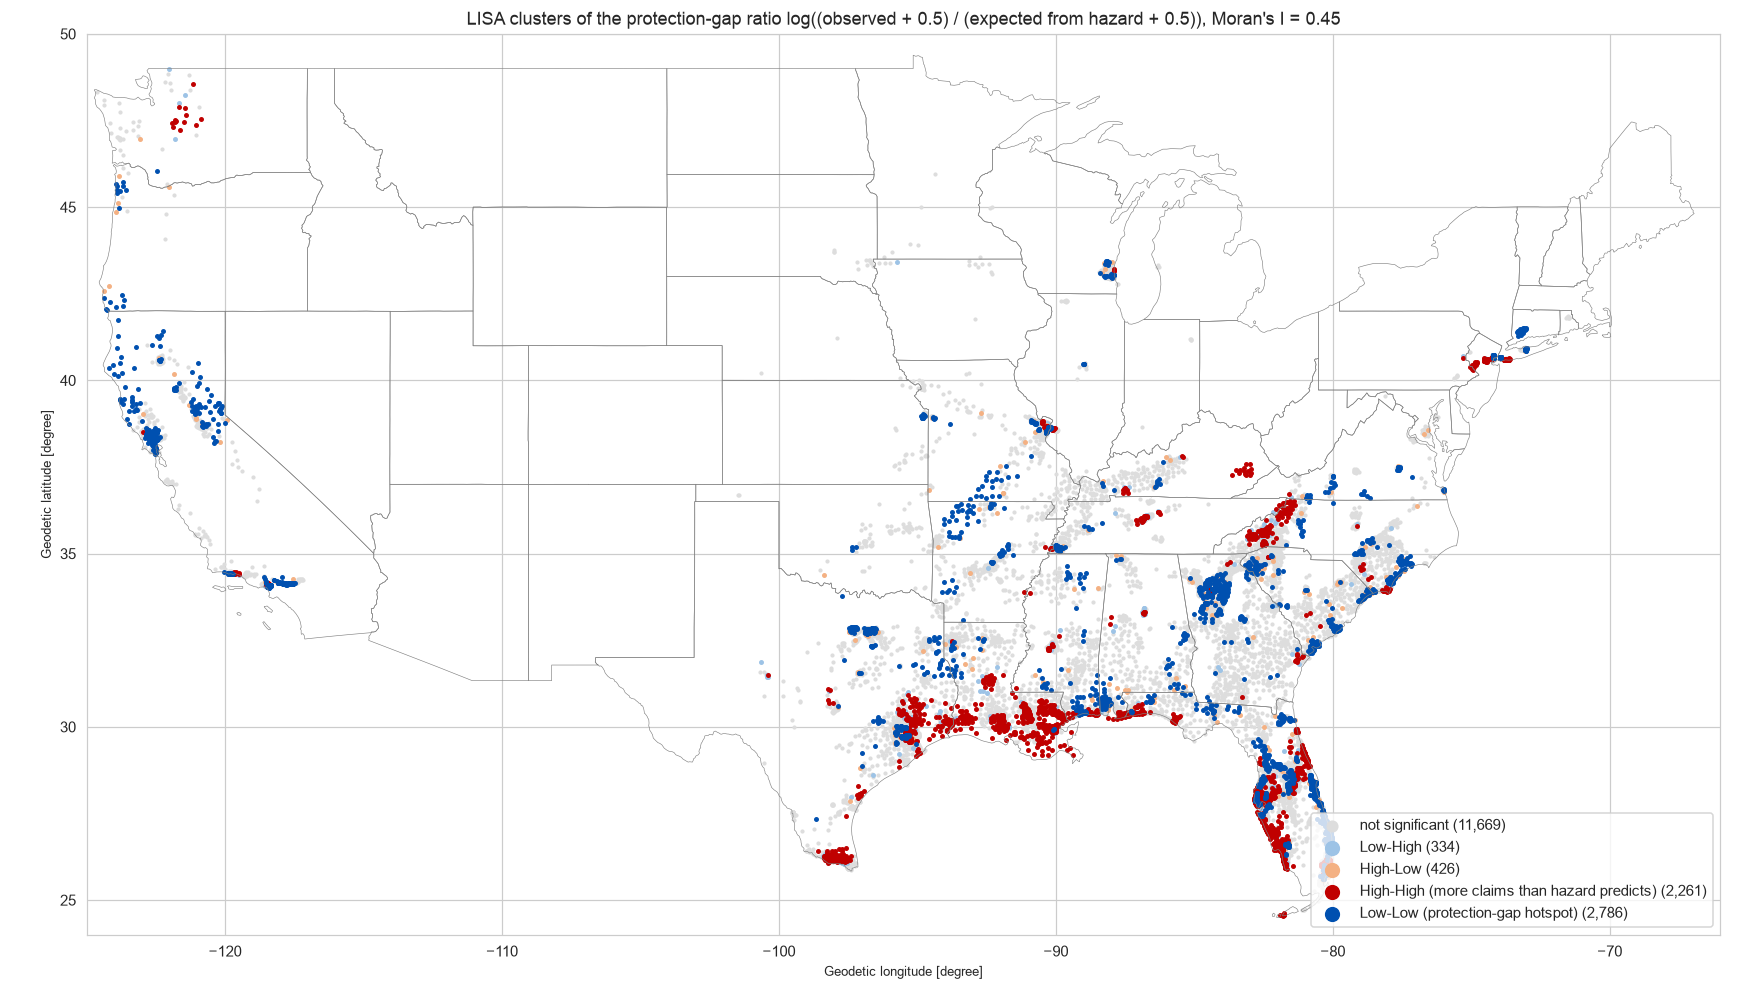

In [9]:
answer_09_rq7 = pd.read_csv(TABLE_DIR / '09_rq7_answer_numbers.csv')
show_rows(answer_09_rq7, ['exposed', 'IRR', 'renter IRR', 'tree', 'take-up', 'claims per 1,000', "Moran's I", 'LISA Low-Low'])
display(Image(filename=str(FIGURE_DIR / '09_rq7_lisa_protection_gap.png'), width=1000))

**Answer.** In 17,476 exposed tracts (hurricane within 100 km or >= 200 mm in 3 days), renter-heavy tracts file about one
third fewer claims per housing unit at the same hazard (IRR 0.68 per SD), through lower take-up (0.86) and fewer claims per
policy (0.78). Income has no net effect after hazard and state controls (IRR 1.00) because higher take-up in richer tracts
(1.34) and fewer claims per policy (0.82) cancel; in the highest-hazard band the poorest tracts insured 14.7% of units vs
44.9% in the richest. Older housing files more claims (1.28). The gap ratio is clustered (Moran's I = 0.45); 2,786 Low-Low
hotspot tracts filed about 1,750 claims where hazard predicted about 51,000, with 7.5% take-up, mostly inland heavy-rain areas.

---
# Section 5: One Figure for the Whole Project: NFIP Only vs NFIP + External Data

Each row is one comparison from notebooks 03-07. Grey = NFIP only, red = NFIP + external data. Where an
event-block bootstrap exists, the red bar is the 95% confidence interval of the external-data model (the NFIP-only
value plus the CI of the gain). Rows without a bar (RQ3, RQ4) have no bootstrap.

                                   comparison  nfip_only  with_external  ci_low  ci_high
RQ1 not paid, ROC-AUC (closed claims, A vs B)      0.737          0.793   0.761    0.866
 RQ1 not paid, PR-AUC (closed claims, A vs B)      0.352          0.427   0.377    0.517
             RQ2 large loss, ROC-AUC (A vs C)      0.812          0.823   0.821    0.853
              RQ2 large loss, PR-AUC (A vs C)      0.411          0.468   0.453    0.478
        RQ5 cause, LightGBM macro-F1 (A vs B)      0.579          0.584   0.563    0.640
     RQ3 clusters, Cramer's V with large loss      0.204          0.251     NaN      NaN
               RQ4 best rule lift, large loss      4.828          5.456     NaN      NaN
                 RQ4 best rule lift, not paid      1.759          2.782     NaN      NaN
       RQ1 not paid, lift in top 10% (A vs B)      3.182          3.899   3.425    4.713
     RQ2 large loss, lift in top 10% (A vs C)      2.571          3.018   2.721    3.200


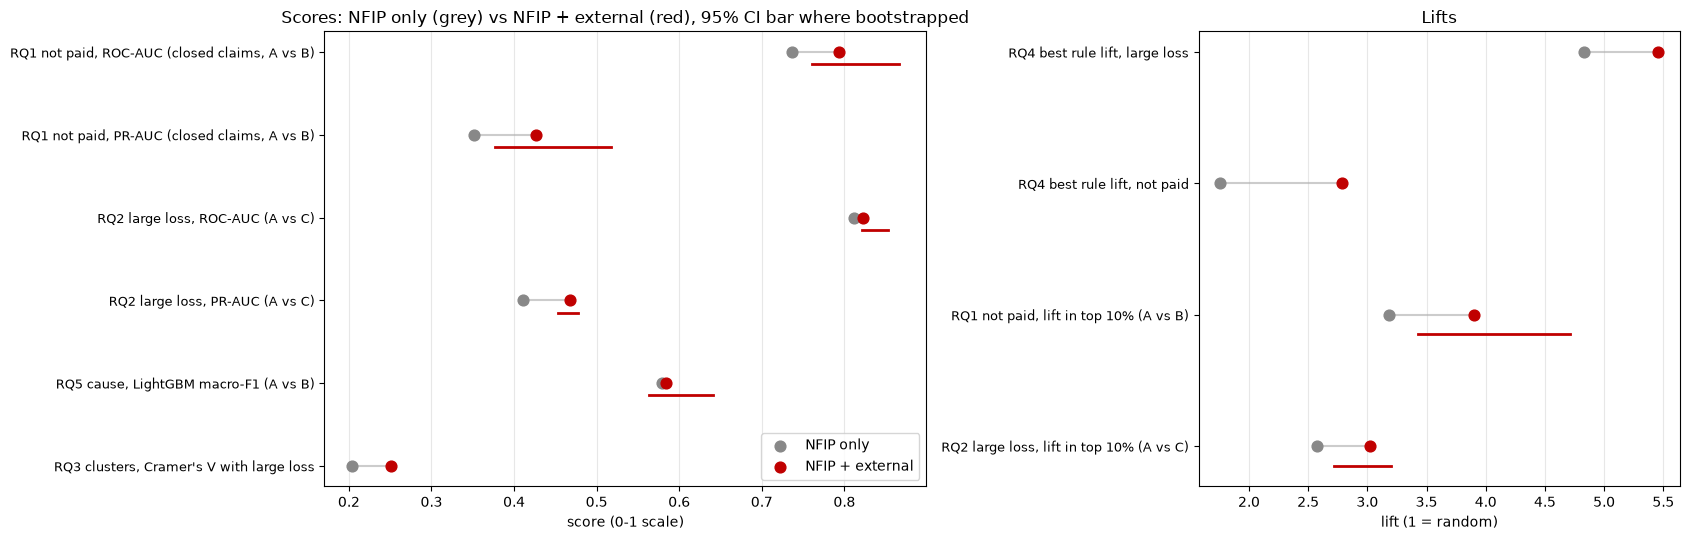

In [10]:
def bootstrap_row(table, metric, model, label, test_set=None):
    subset = table[(table['metric'] == metric)]
    if test_set is not None:
        subset = subset[subset['test_set'] == test_set]
    if 'model' in subset.columns:
        base = subset[subset['gain_vs_baseline'].isna()].iloc[0]['value']
        row = subset[subset['model'] == model].iloc[0]
        return {'comparison': label, 'nfip_only': base, 'with_external': row['value'],
                 'ci_low': base + row['ci_95_low'], 'ci_high': base + row['ci_95_high']}
    row = subset.iloc[0]
    return {'comparison': label, 'nfip_only': row['NFIP_only_A'], 'with_external': row['NFIP_plus_event_B'],
             'ci_low': row['NFIP_only_A'] + row['ci_95_low'], 'ci_high': row['NFIP_only_A'] + row['ci_95_high']}


rq1_boot = pd.read_csv(TABLE_DIR / '03_rq1_refined_bootstrap.csv')
rq2_boot = pd.read_csv(TABLE_DIR / '04_rq2_bootstrap.csv')
rq5_boot = pd.read_csv(TABLE_DIR / '07_rq5_cause_bootstrap.csv')
rq3_progression = pd.read_csv(TABLE_DIR / '05_rq3_progression.csv')
rq4_progression = pd.read_csv(TABLE_DIR / '06_rq4_progression.csv')
score_rows = [
    bootstrap_row(rq1_boot, 'ROC_AUC', None, 'RQ1 not paid, ROC-AUC (closed claims, A vs B)', 'closed claims'),
    bootstrap_row(rq1_boot, 'PR_AUC', None, 'RQ1 not paid, PR-AUC (closed claims, A vs B)', 'closed claims'),
    bootstrap_row(rq2_boot, 'ROC_AUC', 'C. + event + context', 'RQ2 large loss, ROC-AUC (A vs C)'),
    bootstrap_row(rq2_boot, 'PR_AUC', 'C. + event + context', 'RQ2 large loss, PR-AUC (A vs C)'),
    bootstrap_row(rq5_boot, 'macro_F1', 'B. + event', 'RQ5 cause, LightGBM macro-F1 (A vs B)'),
]
large_V = rq3_progression[rq3_progression['outcome'] == 'large_loss_flag']['cramers_V'].tolist()
score_rows.append({'comparison': "RQ3 clusters, Cramer's V with large loss", 'nfip_only': large_V[0], 'with_external': large_V[1],
                   'ci_low': np.nan, 'ci_high': np.nan})
lift_rows = []
for rule_outcome, label in [('OUT_large_loss', 'RQ4 best rule lift, large loss'), ('OUT_not_paid', 'RQ4 best rule lift, not paid')]:
    subset = rq4_progression[rq4_progression['outcome'] == rule_outcome].set_index('allowed items')
    lift_rows.append({'comparison': label, 'nfip_only': subset.loc['NFIP items only', 'best_lift'],
                      'with_external': subset.loc['NFIP + external items', 'best_lift'], 'ci_low': np.nan, 'ci_high': np.nan})
for metric, label in [('lift_top10%', 'RQ1 not paid, lift in top 10% (A vs B)')]:
    lift_rows.append(bootstrap_row(rq1_boot, metric, None, label, 'closed claims'))
lift_rows.append(bootstrap_row(rq2_boot, 'lift_top10%', 'C. + event + context', 'RQ2 large loss, lift in top 10% (A vs C)'))
key_results = pd.DataFrame(score_rows + lift_rows)
key_results.round(3).to_csv(TABLE_DIR / '99_key_results.csv', index=False)
print(key_results.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
for ax, rows_frame, xlabel in [(axes[0], pd.DataFrame(score_rows), 'score (0-1 scale)'), (axes[1], pd.DataFrame(lift_rows), 'lift (1 = random)')]:
    positions = np.arange(len(rows_frame))[::-1]
    ax.scatter(rows_frame['nfip_only'], positions, color='#888888', s=60, label='NFIP only', zorder=3)
    ax.scatter(rows_frame['with_external'], positions, color='#C00000', s=60, label='NFIP + external', zorder=3)
    for position, (_, row) in zip(positions, rows_frame.iterrows()):
        ax.plot([row['nfip_only'], row['with_external']], [position, position], color='#cccccc', zorder=1)
        if pd.notna(row['ci_low']):
            ax.plot([row['ci_low'], row['ci_high']], [position - 0.15, position - 0.15], color='#C00000', lw=2)
    ax.set_yticks(positions)
    ax.set_yticklabels(rows_frame['comparison'], fontsize=9)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', alpha=0.3)
axes[0].legend(loc='lower right')
axes[0].set_title('Scores: NFIP only (grey) vs NFIP + external (red), 95% CI bar where bootstrapped')
axes[1].set_title('Lifts')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '99_key_results_dot_plot.png', dpi=120)
plt.show()

## What the external data changed (honest summary)

| Question | NFIP only | NFIP + external | Verdict |
|---|---|---|---|
| RQ1 not paid, closed claims (ROC / PR-AUC) | 0.737 / 0.352 | 0.793 / 0.427 (event); gain CI above 0 | **Clear gain** from rain and storm data (larger without Helene) |
| RQ2 large loss (ROC / PR-AUC / lift@10%) | 0.812 / 0.411 / 2.57 | 0.823 / 0.468 / 3.02 | **Gain in PR-AUC and lift** (CI above 0), small in ROC |
| RQ3 clusters (Cramer's V with large loss) | 0.204 | 0.251 (+ ACS, NRI, coast) | Small gain |
| RQ4 rules (best lift large loss / not paid) | 4.83 / 1.76 | 5.46 / 2.78 | **Gain** |
| RQ5 cause (LightGBM macro-F1) | 0.579 | 0.584-0.590 | **No clear gain** (bootstrap CI contains 0) |
| Feature reduction (logistic, large loss) | 0.768 ROC | 0.748-0.783 | No gain for a *linear* model |
| RQ7 claims per housing unit (tract level) | not possible without hazard and census data | hazard explains 40% of deviance; ACS adds about 1 point | The question itself needs the external data and the policies file |

The external data helps where the outcome depends on **how hard the flood hit** (payment, large loss, rules). It does
not help where NFIP location fields already carry the same information, and it does not help linear models much.

---
# Section 6: Dead Ends: What I Tried and Dropped

> **Dead ends box.** The project is the story of how I moved towards the answers. These are the things I tried and
> dropped, and why.

| What I tried | What happened | What I did instead |
|---|---|---|
| NFIP v2 API (`FimaNfipClaims`), 1,000 rows per call | v2 is deprecated; the API would need about 2,700 calls | v3 bulk parquet file, frozen as a snapshot (notebook 00) |
| Census API for ACS | it now needs a key | the bulk ACS Summary File tables |
| NFIP-only models for RQ1-RQ3 | weak answers (RQ1 ROC-AUC about 0.73 on new storms) | added PRISM rain, HURDAT2 storms, coast distance, ACS and NRI |
| `buildingReplacementCost` as a "building fact" | its blanks follow the claim process (hidden leak); RQ2 PR-AUC jumps to about 0.57 | excluded from every model, kept only as a leakage demonstration |
| A large-loss line on **payment** | payment is capped by coverage, so it measures the policy | line on **damage** (P90 of 2020-2023) |
| PCA components as model inputs (notebook 02) | lower scores than the selected original features, and no meaning | feature selection (mutual information, permutation importance) |
| ACS/NRI context for RQ1 on the time split | no gain on new storms; neighbourhood values act partly as location IDs | reported honestly; context kept only where it helps (RQ2) |
| State-level models (Ghaedi et al. 2022) | the national model won in all four states | "not reproduced at claim level" |
| RQ3: choosing k with 3 shuffled datasets | the decision flipped between k = 2 and k = 4 from run to run | 20 shuffled datasets + the gap statistic, and a written rule for k |
| External features for the cause model (RQ5) | no gain for LightGBM (lat/lon and flood zone already encode the coast) | kept as a finding; external data helps only k-NN and a small readable tree |
| DBSCAN hotspots with eps = 20 km | separate storms chained into one long hotspot | eps = 12 km after a sensitivity test |
| Negative binomial for claims per policy (RQ7, model c) | the dispersion parameter collapsed to 0 | Poisson GLM with robust standard errors |
| NRI column `RFLD_RISKS` | renamed to `IFLD_RISKS` in NRI v1.20 | updated the code |

---
# Section 7: Limitations

- Notebooks 03-08 model outcomes **given a claim**. Only notebook 09 uses the policies file (policies in force by tract) to look at who files claims at all; private flood insurance is never observed.
- Coordinates are rounded to 0.1 degree (about 11 km). Rain and coast distance are measured at that point.
- **The test period is unusual.** 2024 was dominated by Helene and Milton (about half of the test claims are from Helene), and 2025 is incomplete (reporting lag). The test years hold only about 26 event groups, so the bootstrap confidence intervals are wide.
- **Open claims.** In 2024-2025 many unpaid claims have no non-payment reason (probably still open). The closed-claims checks in notebooks 03 and 04 show that this changes the scores only a little.
- **Probabilities shift between periods.** The large-loss rate in 2024-2025 is about twice the training rate, so the RQ2 probabilities are too low (notebook 04, Section 7.1); rankings are not affected.
- Imputation medians are learned on 2020-2023 before the event-grouped CV (tiny effect, notebook 01, Section 8).
- The adjuster's damage and cause are themselves estimates; damage is also a "bad control" for the equity question (notebook 08).
- ACS values describe neighbourhoods, not policyholders (ecological inference).
- The data is a frozen OpenFEMA snapshot (`tables/00_data_snapshot.json`); a newer download will give slightly different numbers.

---
# Section 8: Glossary

| Term | Meaning (one line) |
|---|---|
| **ROC-AUC** | probability that a random positive claim gets a higher score than a random negative one (0.5 = random, 1 = perfect) |
| **PR-AUC** | area under the precision-recall curve; for a rare class, random = the positive share |
| **Lift (top 10%)** | how many times more positives are in the top 10% of scores than on average; for a rule: confidence / base rate |
| **Brier score** | mean squared error of a predicted probability (lower is better) |
| **Calibration / reliability curve** | plot of predicted probability against the observed rate; a calibrated model lies on the diagonal |
| **Event-block bootstrap** | resampling whole storms (not single claims) with replacement to get a confidence interval |
| **SHAP** | splits one prediction into additive contributions of the features (Shapley values) |
| **Cramer's V** | strength of association between two categorical variables (0 = none, 1 = perfect) |
| **ARI (adjusted Rand index)** | agreement between two clusterings, corrected for chance (0 = chance, 1 = identical) |
| **Silhouette** | how much closer a point is to its own cluster than to the next one (-1 to 1) |
| **Gap statistic** | compares the clustering of the real data with the clustering of reference (noise) data to choose k |
| **Benjamini-Hochberg (BH)** | multiple-testing correction that controls the false discovery rate |
| **Moran's I** | global spatial autocorrelation: do neighbouring areas have similar values? (0 = random) |
| **LISA** | local Moran's I: hot spots (High-High), cold spots (Low-Low) and outliers for each area |
| **Empirical Bayes rate** | a rate pulled towards the overall rate, more strongly for small areas (less noise) |
| **IRR (incidence rate ratio)** | multiplicative change in a count rate for +1 unit (here +1 SD) of a variable; 1 = no effect |
| **Odds ratio (OR)** | multiplicative change in the odds of an event; 1 = no difference |
| **SFHA** | Special Flood Hazard Area: the 1%-annual-chance flood zone on FEMA maps (zones A and V) |
| **Pre-FIRM / post-FIRM** | built before / after the community's first Flood Insurance Rate Map (post-FIRM buildings follow flood rules) |
| **CRS** | Community Rating System: communities that do extra flood work get a premium discount (class 1 best, 10 none) |
| **RR2.0** | Risk Rating 2.0: FEMA's new property-level pricing method (from October 2021) |
| **Take-up** | share of housing units with an NFIP policy in force |
| **Bad control** | a control variable that is itself affected by the thing we study; controlling for it hides part of the effect |

---
# Section 9: References

**Data**
1. FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3*. https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3 (bulk file NfipClaimsV3.parquet, accessed 2026).
2. PRISM Climate Group, Oregon State University. *AN daily precipitation, 4 km*. https://prism.oregonstate.edu (data: https://data.prism.oregonstate.edu/time_series/us/an/4km/ppt/daily/).
3. Landsea, C. W. & Franklin, J. L. (2013). Atlantic hurricane database uncertainty and presentation of a new database format (HURDAT2). *Monthly Weather Review* 141, 3576-3592. Data: https://www.nhc.noaa.gov/data/hurdat/
4. U.S. Census Bureau. *American Community Survey 2019-2023 5-year estimates, Summary File*. https://www2.census.gov/programs-surveys/acs/summary_file/2023/
5. U.S. Census Bureau. *2023 Cartographic Boundary Files (counties, states)*. https://www2.census.gov/geo/tiger/GENZ2023/
6. FEMA. *National Risk Index, v1.20, county table*. https://www.fema.gov/flood-maps/products-tools/national-risk-index
7. Natural Earth. *1:10m coastline*. https://www.naturalearthdata.com
8. FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Policies - v3*. https://www.fema.gov/openfema-data-page/nfip-redacted-policies-v3 (notebook 09).
9. U.S. Census Bureau. *2020 Census Tract to 2010 Census Tract Relationship File* and *2023 Gazetteer Files*. https://www.census.gov/geographies/reference-files/time-series/geo/relationship-files.html (notebook 09).

**Published research reproduced or extended**
10. Nelson-Mercer, B., Kim, T., Tran, V. N. & Ivanov, V. (2025). Pluvial flood impacts and policyholder responses throughout the United States. *npj Natural Hazards*. https://www.nature.com/articles/s44304-025-00058-7 (reproduced in notebook 07).
11. Ghaedi, H., Reilly, A. C., Baroud, H., Perrucci, D. V. & Ferreira, C. M. (2022). Predicting flood damage using the flood peak ratio and Giovanni Flooded Fraction. *PLOS ONE* 17(8). https://pmc.ncbi.nlm.nih.gov/articles/PMC9348728/ (reproduced in notebook 04).
12. Urban Institute. *Housing Resilience in Greater New Orleans*. https://www.urban.org/research/publication/housing-resilience-greater-new-orleans (finding repeated in notebook 08).
13. *Are Underserved Populations Left Out of National Flood Mitigation Efforts and Facing Greater Impact? A Method to Assess Racial Inequality at the Census Tract Level* (2023). *Journal of Climate Resilience and Justice* 1, 78-92. https://research.utwente.nl/en/publications/are-underserved-populations-left-out-of-national-flood-mitigation/ (notebook 08).
14. Kousky, C. & Michel-Kerjan, E. (2017). Examining flood insurance claims in the United States: Six key findings. *Journal of Risk and Insurance* 84(3), 819-850. https://doi.org/10.1111/jori.12106 (features and payment determinants, notebooks 01, 03).
15. Salas, J., Saha, A. & Ravela, S. (2023). Learning inter-annual flood loss risk models from historical flood insurance claims. *Journal of Environmental Management* 347, 118862. https://doi.org/10.1016/j.jenvman.2023.118862 (rain added to NFIP; gradient boosting; notebooks 03-04).
16. Bowers, C., Serafin, K. A. & Baker, J. W. (2024). Uncovering drivers of atmospheric river flood damage using interpretable machine learning. *Natural Hazards Review* 25(3). https://doi.org/10.1061/nhrefo.nheng-1995 (storm + exposure features, SHAP-style interpretation).
17. Liu, C. & Mostafavi, A. (2025). FloodGenome: interpretable machine learning for property flood-risk predisposition. *Environmental Research: Infrastructure and Sustainability*. https://doi.org/10.1088/2634-4505/adb800 (clustering of flood-risk features, notebook 05).
18. Liu, C.-F., Huang, L., Yin, K., Brody, S. & Mostafavi, A. (2024). FloodDamageCast: building flood damage nowcasting with machine learning and data augmentation. *International Journal of Disaster Risk Reduction*. https://doi.org/10.1016/j.ijdrr.2024.104971
19. Kraft, L. L., Villarini, G., Czajkowski, J., Zimmerman, D. & Amorim, R. S. (2025). Developing a spatial regression model framework for insured flood losses in Houston. *ASCE OPEN* 3(1). https://ascelibrary.org/doi/10.1061/AOMJAH.AOENG-0044 (Moran's I, notebook 07).
20. Stacked ensemble approach for predicting residential flood insurance claims across Indiana (2020). AGU Fall Meeting abstract. https://studio.m-anage.com/agu/fm20/webprogram/Paper760856.html (adjusted R2 about 0.22: the problem is hard).
21. Amornsiripanitch, N., Biswas, S., Orellana-Li, J. & Zink, D. (2025). Measuring flood underinsurance in the USA. *Nature Climate Change* 15. https://www.nature.com/articles/s41558-025-02396-w (notebook 09).

**Context: NFIP policy and pricing**
22. Mulder, P. & Kousky, C. (2023). Risk Rating without information provision. *AEA Papers and Proceedings* 113, 299-303. https://www.aeaweb.org/articles?id=10.1257/pandp.20231102 (Risk Rating 2.0, notebook 01).
23. Gourevitch, J., Snyder, M. & Kousky, C. (2025). Effects of risk-based pricing reform on flood insurance uptake. *Journal of Catastrophe Risk and Resilience*. https://journalofcrr.com/research/03-07-gourevitch-et-al/
24. Ortega, F. & Petkov, I. (2025). To improve is to change? The effects of Risk Rating 2.0 on flood insurance demand. *Journal of Environmental Economics and Management* 134, 103228. https://docs.iza.org/dp17021.pdf
25. Bradt, J., Kousky, C. & Wing, O. (2021). Voluntary purchases and adverse selection in the market for flood insurance. *Journal of Environmental Economics and Management* 110, 102515. https://doi.org/10.1016/j.jeem.2021.102515
26. U.S. GAO (2023). *National Flood Insurance Program: FEMA's new rate-setting methodology...* GAO-23-105977. https://www.gao.gov/products/gao-23-105977

**Methods**
27. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR* 12, 2825-2830.
28. Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.
29. Lundberg, S. M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). *NeurIPS*.
30. van der Maaten, L. & Hinton, G. (2008). Visualizing data using t-SNE. *JMLR* 9, 2579-2605.
31. Ester, M., Kriegel, H.-P., Sander, J. & Xu, X. (1996). A density-based algorithm for discovering clusters (DBSCAN). *KDD*.
32. Agrawal, R. & Srikant, R. (1994). Fast algorithms for mining association rules. *VLDB*. Han, J., Pei, J. & Yin, Y. (2000). Mining frequent patterns without candidate generation (FP-Growth). *SIGMOD*.
33. Cameron, A. C. & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press (Poisson / negative binomial, notebook 09).
34. Anselin, L. (1995). Local indicators of spatial association - LISA. *Geographical Analysis* 27(2), 93-115.
35. Raschka, S. (2018). MLxtend. *Journal of Open Source Software* 3(24), 638.
36. Rey, S. J. & Anselin, L. (2007). PySAL: a Python library of spatial analytical methods. *Review of Regional Studies* 37(1), 5-27.
37. Tibshirani, R., Walther, G. & Hastie, T. (2001). Estimating the number of clusters in a data set via the gap statistic. *Journal of the Royal Statistical Society B* 63(2), 411-423 (notebook 05).
38. Benjamini, Y. & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society B* 57(1), 289-300 (notebook 06).
39. Assuncao, R. M. & Reis, E. A. (1999). A new proposal to adjust Moran's I for population density. *Statistics in Medicine* 18(16), 2147-2162 (empirical Bayes Moran's I, notebook 07).
40. Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review* 78(1), 1-3 (calibration, notebooks 03-04).
41. Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall (event-block bootstrap, notebooks 03, 04, 07).